In [1]:
# ==============================================================================
# ENVIRONMENT SETUP & EVALUATION METRICS
# ==============================================================================
import pandas as pd
import numpy as np
import warnings
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.ensemble import RandomForestRegressor
from sklearn.svm import SVR
from sklearn.model_selection import KFold
from sklearn.metrics import mean_absolute_error, cohen_kappa_score
from scipy.sparse import hstack, csr_matrix

warnings.filterwarnings('ignore')

def calculate_qwk(y_true, y_pred, scale=10):
    """
    Calculates Quadratic Weighted Kappa (QWK) for continuous regression outputs.
    Since targets are normalized floats [0.0, 1.0], they are projected onto a
    discrete 0-10 ordinal scale to mathematically satisfy the QWK calculation.
    """
    y_true_int = np.round(y_true * scale).astype(int)
    y_pred_int = np.round(y_pred * scale).astype(int)

    return cohen_kappa_score(y_true_int, y_pred_int, weights='quadratic')

In [ ]:
# ==============================================================================
# DATA INGESTION & HYBRID FEATURE FUSION
# ==============================================================================
# NOTE FOR REVIEWERS: Set `base_path` to the repository root directory.
base_path = '..'
df = pd.read_csv(f'{base_path}/data/final_preprocessed_data.csv')

# Standardize text column nomenclature for downstream pipelines
df.rename(columns={'clean_text': 'clean_essay_text'}, inplace=True)

print("Engineering Hybrid Feature Space...")

# 1. Isolate Target Variable
y = df['final_target_score'].values

# 2. Text Vectorization (TF-IDF)
# Constrained to 1,500 dimensions to balance against the 5 dense traits
tfidf = TfidfVectorizer(max_features=1500, ngram_range=(1, 2), stop_words='english')
X_text = tfidf.fit_transform(df['clean_essay_text'])

# 3. Dense Pseudo-Trait Extraction
trait_cols = [
    'trait_1_mechanical_density',
    'trait_2_casing_density',
    'trait_3_lexical_richness',
    'trait_4_prompt_relevance',
    'trait_5_word_count'
]
X_traits = csr_matrix(df[trait_cols].values)

# 4. Multimodal Fusion
# .tocsr() is called once here to prevent memory overhead during cross-validation
X_final = hstack([X_text, X_traits]).tocsr()

print(f"Sparse TF-IDF Matrix : {X_text.shape}")
print(f"Dense Trait Tensor   : {X_traits.shape}")
print(f"Fused Input Space    : {X_final.shape}")

Engineering Hybrid Feature Space...
Sparse TF-IDF Matrix : (308, 1500)
Dense Trait Tensor   : (308, 5)
Fused Input Space    : (308, 1505)


In [ ]:
# ==============================================================================
# TRADITIONAL BASELINE EVALUATION (5-FOLD CV)
# ==============================================================================
print("Initializing 5-Fold Cross-Validation...")

rf_model = RandomForestRegressor(n_estimators=100, random_state=42)
svr_model = SVR(kernel='linear', C=1.0)

kf = KFold(n_splits=5, shuffle=True, random_state=42)

rf_maes, rf_qwks = [], []
svr_maes, svr_qwks = [], []

for fold, (train_index, test_index) in enumerate(kf.split(X_final), 1):
    X_train, X_test = X_final[train_index], X_final[test_index]
    y_train, y_test = y[train_index], y[test_index]

    # --- Train & Predict: Random Forest ---
    rf_model.fit(X_train, y_train)
    rf_preds = rf_model.predict(X_test)
    rf_maes.append(mean_absolute_error(y_test, rf_preds))
    rf_qwks.append(calculate_qwk(y_test, rf_preds))

    # --- Train & Predict: Support Vector Regressor ---
    svr_model.fit(X_train, y_train)
    svr_preds = svr_model.predict(X_test)
    svr_maes.append(mean_absolute_error(y_test, svr_preds))
    svr_qwks.append(calculate_qwk(y_test, svr_preds))

    print(f"[Fold {fold}/5] Evaluated.")

print("\n==================================================")
print("FINAL BASELINE PERFORMANCE (OUT-OF-FOLD MEAN)")
print("==================================================")
print(f"Random Forest (Non-Linear) -> MAE: {np.mean(rf_maes):.4f} | QWK: {np.mean(rf_qwks):.4f}")
print(f"SVR (Linear Kernel)        -> MAE: {np.mean(svr_maes):.4f} | QWK: {np.mean(svr_qwks):.4f}")

Initializing 5-Fold Cross-Validation...
[Fold 1/5] Evaluated.
[Fold 2/5] Evaluated.
[Fold 3/5] Evaluated.
[Fold 4/5] Evaluated.
[Fold 5/5] Evaluated.

FINAL BASELINE PERFORMANCE (OUT-OF-FOLD MEAN)
Random Forest (Non-Linear) -> MAE: 0.1053 | QWK: 0.6850
SVR (Linear Kernel)        -> MAE: 0.1179 | QWK: 0.6351


In [ ]:
# ==============================================================================
# HYPERPARAMETER OPTIMIZATION (GRID SEARCH)
# ==============================================================================
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import make_scorer
import time

print("Initializing Exhaustive Grid Search for Random Forest...")
start_time = time.time()

# 1. Custom QWK Scorer
qwk_scorer = make_scorer(calculate_qwk, greater_is_better=True)

# 2. Hyperparameter Space
param_grid = {
    'n_estimators': [100, 200, 300],          # Number of trees
    'max_depth': [None, 10, 20, 30],          # Maximum tree depth
    'min_samples_split': [2, 5, 10],          # Minimum samples to split a node
    'min_samples_leaf': [1, 2, 4],            # Minimum samples at a leaf
    'max_features': ['sqrt', 1.0]             # Feature fraction per split
}

# 3. Grid Search Execution
grid_search = GridSearchCV(
    estimator=RandomForestRegressor(random_state=42),
    param_grid=param_grid,
    scoring=qwk_scorer,
    cv=kf,
    n_jobs=-1,
    verbose=1
)

grid_search.fit(X_final, y)
best_rf_model = grid_search.best_estimator_

print("\n==================================================")
print("GRID SEARCH COMPLETE")
print("==================================================")
print(f"Execution Time     : {(time.time() - start_time) / 60:.2f} minutes")
print(f"Optimal QWK Score  : {grid_search.best_score_:.4f}")
print("Optimal Parameters :")
for param, value in grid_search.best_params_.items():
    print(f" - {param}: {value}")

Initializing Exhaustive Grid Search for Random Forest...
Fitting 5 folds for each of 216 candidates, totalling 1080 fits

GRID SEARCH COMPLETE
Execution Time     : 22.51 minutes
Optimal QWK Score  : 0.6987
Optimal Parameters :
 - max_depth: 10
 - max_features: 1.0
 - min_samples_leaf: 2
 - min_samples_split: 2
 - n_estimators: 200


Generating Out-of-Fold predictions for diagnostic plotting...


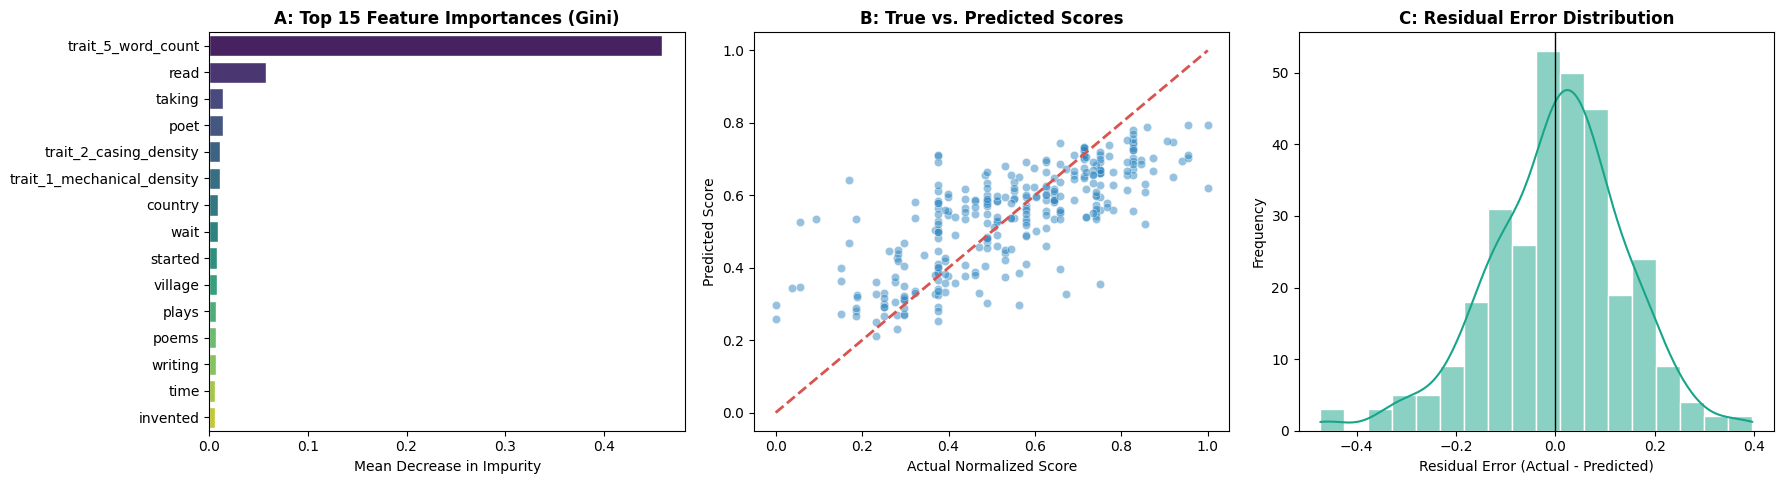

In [ ]:
# ==============================================================================
# CHAMPION MODEL DIAGNOSTICS & VISUALIZATION
# ==============================================================================
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import cross_val_predict

print("Generating Out-of-Fold predictions for diagnostic plotting...")
tuned_preds = cross_val_predict(best_rf_model, X_final, y, cv=kf, n_jobs=-1)
residuals = y - tuned_preds

# Feature Importance Extraction
tfidf_feature_names = tfidf.get_feature_names_out()
all_feature_names = np.concatenate([tfidf_feature_names, trait_cols])

importance_df = pd.DataFrame({
    'Feature': all_feature_names,
    'Importance': best_rf_model.feature_importances_
}).sort_values(by='Importance', ascending=False).head(15)

# Render 1x3 Professional Grid
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
sns.set_theme(style="whitegrid")

# Plot A: Feature Importances
sns.barplot(x='Importance', y='Feature', data=importance_df, palette='viridis', ax=axes[0])
axes[0].set_title('A: Top 15 Feature Importances (Gini)', fontweight='bold')
axes[0].set_xlabel('Mean Decrease in Impurity')
axes[0].set_ylabel('')

# Plot B: True vs. Predicted
sns.scatterplot(x=y, y=tuned_preds, alpha=0.5, color='#2E86C1', ax=axes[1])
axes[1].plot([0, 1], [0, 1], color='#D9534F', linestyle='--', linewidth=2)
axes[1].set_title('B: True vs. Predicted Scores', fontweight='bold')
axes[1].set_xlabel('Actual Normalized Score')
axes[1].set_ylabel('Predicted Score')

# Plot C: Residual Distribution
sns.histplot(residuals, kde=True, color='#17A589', ax=axes[2])
axes[2].axvline(0, color='black', linestyle='-', linewidth=1)
axes[2].set_title('C: Residual Error Distribution', fontweight='bold')
axes[2].set_xlabel('Residual Error (Actual - Predicted)')
axes[2].set_ylabel('Frequency')

plt.tight_layout()
plt.savefig('rf_champion_diagnostics.pdf', format='pdf', bbox_inches='tight')
plt.show()

In [ ]:
# ==============================================================================
# ARTIFACT & PREDICTION EXPORT PIPELINE
# ==============================================================================
import joblib
import os

# Target directory
export_dir = f'{base_path}/artifacts/02_Traditional_ML_Baselines'
os.makedirs(export_dir, exist_ok=True)

print("1. Exporting Serialized Models and Vectorizers...")
joblib.dump(best_rf_model, f'{export_dir}/BSSD_aes_rf_tuned_model.joblib')
joblib.dump(tfidf, f'{export_dir}/BSSD_aes_tfidf_vectorizer.joblib')

print("2. Generating and Exporting Out-Of-Fold (OOF) Predictions...")
# Generate SVR predictions (RF tuned predictions were already captured in Cell 5)
svr_oof_preds = cross_val_predict(svr_model, X_final, y, cv=kf, n_jobs=-1)

# Save Random Forest OOF Predictions
rf_df = pd.DataFrame({'rf_oof_preds': tuned_preds})
rf_df.to_csv(f'{export_dir}/rf_predictions.csv', index=False)

# Save SVR OOF Predictions
svr_df = pd.DataFrame({'svr_oof_preds': svr_oof_preds})
svr_df.to_csv(f'{export_dir}/svr_predictions.csv', index=False)

print("Success! All artifacts and OOF predictions archived.")

1. Exporting Serialized Models and Vectorizers...
2. Generating and Exporting Out-Of-Fold (OOF) Predictions...
Success! All artifacts and OOF predictions archived.
